# Bases fortes e fracas: pH e grau de ionização
### Funções inorgânicas — bases

**Objetivo:** Calcular o pH de hidróxidos fortes e de bases fracas, levando em conta o número de hidroxilas e o grau de ionização.

### Como usar este notebook

Execute as células na ordem, de cima para baixo. As células Markdown apresentam os conceitos; as células de código fazem as contas e geram as visualizações com **RDKit**, **py3Dmol** e **Matplotlib**.

> **Moléculas em 3D:** clique na figura e **arraste o mouse** — ela gira em 360° em qualquer direção. Use a roda do mouse (ou dois dedos no celular) para dar zoom. As cores seguem a convenção dos químicos (C = cinza, H = branco, O = vermelho, N = azul, S = amarelo, Cl = verde, Na = violeta).

In [1]:
# @title Preparar o ambiente (só precisa rodar uma vez)
import importlib.util, subprocess, sys

def _tem(modulo):
    return importlib.util.find_spec(modulo) is not None

for pacote in ("rdkit", "py3Dmol"):
    if not _tem(pacote):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import rdkit, py3Dmol
print("rdkit", rdkit.__version__, "| py3Dmol", py3Dmol.__version__)

rdkit 2026.09.2 | py3Dmol 3.0.0


## 1. Conceito principal

Classificar uma base é mais simples do que parece, porque em água existem poucas bases realmente fortes:

**Bases fortes (dissociam 100%)** — os hidróxidos dos metais alcalinos e dos alcalino-terrosos mais solúveis:

$$
\mathrm{LiOH,\ NaOH,\ KOH,\ Ca(OH)_2,\ Ba(OH)_2,\ Sr(OH)_2}
$$

**Bases fracas (dissociam pouco)** — a amônia, as aminas e os ânions de ácidos fracos (carbonato, bicarbonato, acetato, fosfato).

Para uma base genérica $\mathrm{B}$ com concentração $c$, o equilíbrio

$$
\mathrm{B + H_2O \rightleftharpoons BH^+ + OH^-}
\qquad
\boxed{K_b = \frac{x^2}{c - x},\qquad x \approx \sqrt{K_b\,c}\ \text{(se } x \ll c)}
$$

e o **grau de ionização** (ou grau de dissociação) é

$$
\boxed{\alpha = \frac{[\mathrm{OH^-}]}{c}} \qquad (\times 100\%)
$$

Note que a base forte "não tem $K_b$": como a reação vai até o fim, seria infinito. Escrevemos simplesmente $\mathrm{NaOH \rightarrow Na^+ + OH^-}$ com seta simples.

## 2. Exemplo resolvido passo a passo

Dissolvem-se $0{,}40\ \mathrm{g}$ de $\mathrm{NaOH}$ em água até $100\ \mathrm{mL}$.

**Passo 1 — massa molar e número de mols.**

$$
M(\mathrm{NaOH}) = 23{,}00 + 16{,}00 + 1{,}008 = 40{,}01\ \mathrm{g/mol}
$$
$$
n = \frac{m}{M} = \frac{0{,}40}{40{,}01} = 1{,}0\times10^{-2}\ \mathrm{mol}
$$

**Passo 2 — concentração.**

$$
c = \frac{n}{V} = \frac{1{,}0\times10^{-2}}{0{,}100} = 0{,}100\ \mathrm{mol/L}
$$

**Passo 3 — pH (base forte, um $\mathrm{OH^-}$ por fórmula).**

$$
[\mathrm{OH^-}] = 0{,}100\ \mathrm{mol/L}
\quad\Rightarrow\quad
\mathrm{pOH} = 1{,}00
\quad\Rightarrow\quad
\mathrm{pH} = \boxed{13{,}00}
$$

**Passo 4 — e se fosse $\mathrm{Ca(OH)_2}$?** Aí cada fórmula libera **dois** $\mathrm{OH^-}$:
$[\mathrm{OH^-}] = 2c = 0{,}200\ \mathrm{mol/L}$, $\mathrm{pOH} = 0{,}70$, $\mathrm{pH} = 13{,}30$.

## 3. Conferindo o cálculo com Python

In [2]:
# @title Preparo de solução de NaOH
import math
from rdkit import Chem
from rdkit.Chem import Descriptors

M_NAOH = Descriptors.MolWt(Chem.MolFromSmiles("[Na+].[OH-]"))
massa = 0.40           # g
volume = 0.100         # L

n = massa / M_NAOH
c = n / volume
poh = -math.log10(c)
ph = 14 - poh

print(f"M(NaOH) = {M_NAOH:.2f} g/mol")
print(f"n = {n:.4f} mol")
print(f"c = {c:.4f} mol/L")
print(f"pOH = {poh:.2f}   pH = {ph:.2f}")

# Ca(OH)2: dois OH- por fórmula
oh_calcio = 2 * c
print(f"\nSe fosse Ca(OH)2: [OH-] = {oh_calcio:.3f} mol/L  ->  pH {14 + math.log10(oh_calcio):.2f}")

M(NaOH) = 40.00 g/mol
n = 0.0100 mol
c = 0.1000 mol/L
pOH = 1.00   pH = 13.00

Se fosse Ca(OH)2: [OH-] = 0.200 mol/L  ->  pH 13.30


## 4. Visualização

### 4.1 Hidróxido de sódio em 3D — arraste para girar

O $\mathrm{NaOH}$ é um composto **iônico**: o sódio cede o elétron para a hidroxila e os dois íons se atraem. No 3D aparecem as duas espécies separadas, que é exatamente o que acontece na solução.

In [3]:
# @title Molécula 3D interativa — arraste com o mouse para girar 360°
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

def molecula_3d(smiles, largura=680, altura=440):
    """SMILES -> visualização 3D interativa (arrastar = girar, roda = zoom)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    mol = Chem.AddHs(mol)                      # H explícitos: aparecem na figura

    parametros = AllChem.ETKDGv3()
    parametros.randomSeed = 0xC0FFEE           # mesmo desenho em toda execução
    if AllChem.EmbedMolecule(mol, parametros) != 0:
        raise RuntimeError(f"não foi possível gerar a geometria 3D de {smiles!r}")

    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol)      # relaxa a estrutura
    else:
        AllChem.UFFOptimizeMolecule(mol)       # cobre íons sem parâmetros MMFF

    visor = py3Dmol.view(width=largura, height=altura)
    visor.addModel(Chem.MolToMolBlock(mol), "mol")
    visor.setStyle({"stick": {"radius": 0.13, "colorscheme": "Jmol"},
                    "sphere": {"scale": 0.28, "colorscheme": "Jmol"}})
    visor.setBackgroundColor("#ffffff")
    visor.zoomTo()
    return visor

molecula_3d("[Na+].[OH-]")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.2 Hidróxido de cálcio em 3D

O $\mathrm{Ca(OH)_2}$ tem **dois** grupos hidroxila por unidade de fórmula: por isso é uma base mais "cáustica" por mol de sal dissolvido. É o pó usado na calda bordalesa e na pintura a cal.

In [4]:
molecula_3d("[Ca+2].[OH-].[OH-]")

[16:36:05] UFFTYPER: Unrecognized atom type: Ca+2 (0)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.3 Os dois em 2D, com os risquinhos

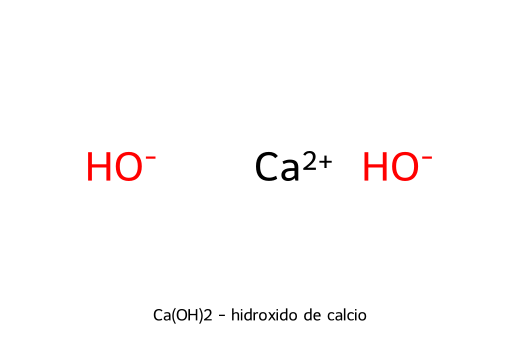

In [5]:
# @title Estrutura 2D com os risquinhos das ligações
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

rdDepictor.SetPreferCoordGen(True)   # layout 2D no estilo de livro didático

def estrutura_2d(smiles, legenda="", largura=520, altura=360, mostrar_h=False):
    """SMILES -> SVG. Um traço = simples, dois = dupla, três = tripla.

    A legenda fica em ASCII porque o desenho do RDKit corrompe acento e
    subscrito (para título bonito, use matplotlib).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    if mostrar_h:
        mol = Chem.AddHs(mol)
    rdDepictor.Compute2DCoords(mol)

    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.drawOptions().padding = 0.10
    desenho.DrawMolecule(mol, legend=legenda)
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_2d("[Na+].[OH-]", legenda="NaOH - hidroxido de sodio")
estrutura_2d("[Ca+2].[OH-].[OH-]", legenda="Ca(OH)2 - hidroxido de calcio")

### 4.4 Galeria de hidróxidos comuns

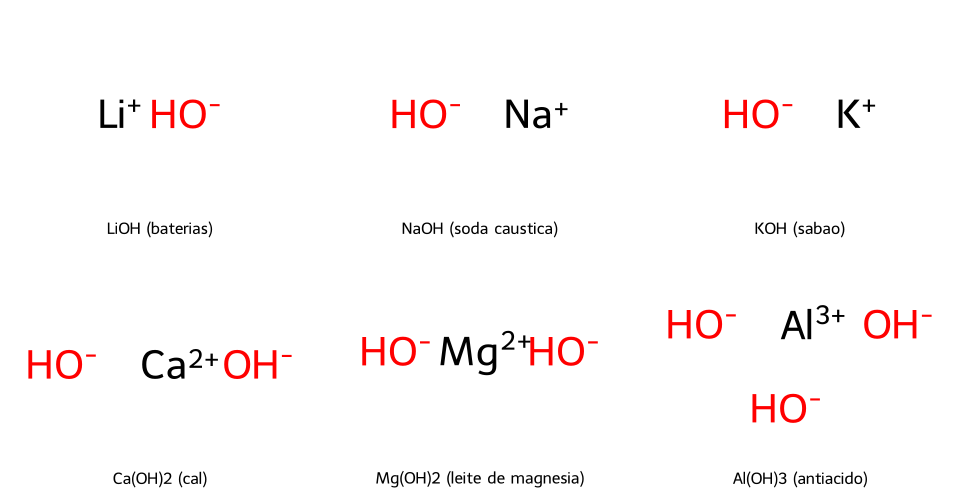

In [6]:
# @title Hidróxidos do dia a dia
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import SVG

hidroxidos = [
    ("LiOH (baterias)", "[Li+].[OH-]"),
    ("NaOH (soda caustica)", "[Na+].[OH-]"),
    ("KOH (sabao)", "[K+].[OH-]"),
    ("Ca(OH)2 (cal)", "[Ca+2].[OH-].[OH-]"),
    ("Mg(OH)2 (leite de magnesia)", "[Mg+2].[OH-].[OH-]"),
    ("Al(OH)3 (antiacido)", "[Al+3].[OH-].[OH-].[OH-]"),
]
imagem = Draw.MolsToGridImage([Chem.MolFromSmiles(s) for _, s in hidroxidos],
                              molsPerRow=3, subImgSize=(320, 250),
                              legends=[nome for nome, _ in hidroxidos], useSVG=True)
imagem if hasattr(imagem, "data") else SVG(imagem)

### 4.5 Grau de ionização × concentração

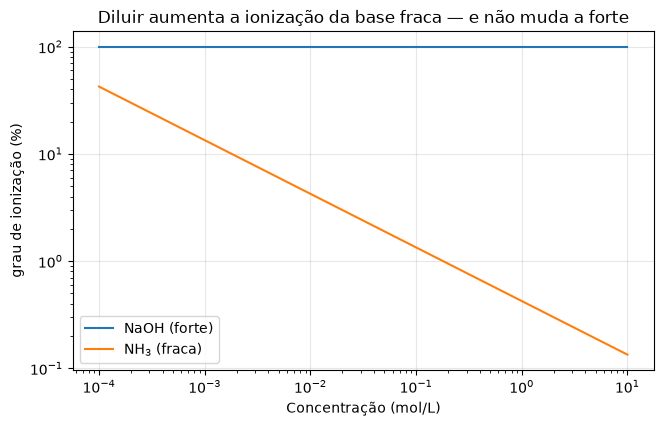

In [7]:
# @title Base forte contra base fraca
import numpy as np
import matplotlib.pyplot as plt

KB = 1.8e-5          # amônia
concentracoes = np.logspace(-4, 1, 100)
alfa_forte = np.full_like(concentracoes, 100.0)          # base forte: sempre 100%
alfa_fraca = 100 * np.sqrt(KB * concentracoes) / concentracoes

plt.figure(figsize=(7.5, 4.4))
plt.plot(concentracoes, alfa_forte, label="NaOH (forte)")
plt.plot(concentracoes, alfa_fraca, label="NH$_3$ (fraca)")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Concentração (mol/L)")
plt.ylabel("grau de ionização (%)")
plt.title("Diluir aumenta a ionização da base fraca — e não muda a forte")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 4.6 A "força" de cada hidróxido em termos de pH

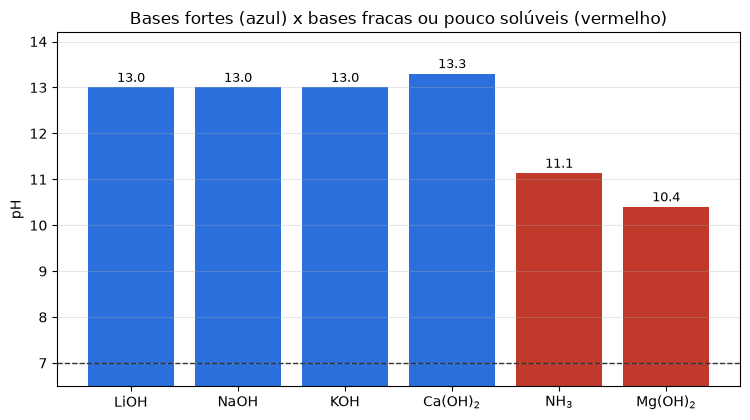

In [8]:
# @title pH de soluções 0,1 mol/L
bases = ["LiOH", "NaOH", "KOH", "Ca(OH)$_2$", "NH$_3$", "Mg(OH)$_2$"]
# Mg(OH)2 é pouco solúvel (~0,0002 mol/L), por isso o pH não chega ao teórico
ph_bases = [13.0, 13.0, 13.0, 13.3, 11.13, 10.4]

plt.figure(figsize=(7.6, 4.3))
cores = ["#2a6fdb"] * 4 + ["#c0392b"] * 2
plt.bar(bases, ph_bases, color=cores)
for i, valor in enumerate(ph_bases):
    plt.annotate(f"{valor:.1f}", (i, valor), xytext=(0, 4), textcoords="offset points",
                 ha="center", fontsize=9)
plt.axhline(7, color="#333", linestyle="--", linewidth=1)
plt.ylim(6.5, 14.2)
plt.ylabel("pH")
plt.title("Bases fortes (azul) x bases fracas ou pouco solúveis (vermelho)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Como interpretar o resultado

- O pH de uma base forte depende só da concentração e do **número de hidroxilas** por fórmula. O $\mathrm{Ca(OH)_2}$ rende o dobro de $\mathrm{OH^-}$ do $\mathrm{NaOH}$ na mesma molaridade.
- A base fraca tem $\alpha$ pequeno e cresce ao diluir (lei de Ostwald): menos choques entre as espécies, o equilíbrio se desloca para o lado ionizado.
- $0{,}1\ \mathrm{mol/L}$ de amônia dá pH $\approx 11{,}1$: base fraca **nunca** chega perto de 14.
- Um hidróxido pode ser "forte" e mesmo assim dar pH moderado se for **pouco solúvel** — é o caso do $\mathrm{Mg(OH)_2}$ do leite de magnésia e do $\mathrm{Al(OH)_3}$.

## 6. Exercício de fixação

Qual a massa de $\mathrm{KOH}$ necessária para preparar $500\ \mathrm{mL}$ de solução de pH 12,0? (Considere base forte e $M = 56{,}11\ \mathrm{g/mol}$.)

In [9]:
# @title Exercício
M_KOH = 56.11
V_EX = 0.500
poh_alvo = 14 - 12.0            # = 2,0
oh_alvo = 10 ** (-poh_alvo)     # mol/L
n_ex = oh_alvo * V_EX           # 1 OH- por fórmula
m_ex = n_ex * M_KOH

print(f"pOH alvo = {poh_alvo:.1f}  ->  [OH-] = {oh_alvo:.4f} mol/L")
print(f"n(KOH)  = {n_ex:.4f} mol")
print(f"massa   = {m_ex:.2f} g")

pOH alvo = 2.0  ->  [OH-] = 0.0100 mol/L
n(KOH)  = 0.0050 mol
massa   = 0.28 g


## 7. Resumo

- Bases fortes: hidróxidos de metais alcalinos (e $\mathrm{Ca(OH)_2}$, $\mathrm{Ba(OH)_2}$, $\mathrm{Sr(OH)_2}$).
- Bases fracas: amônia, aminas e ânions de ácidos fracos ($K_b$ pequeno).
- $[\mathrm{OH^-}] = c \times (\text{nº de } \mathrm{OH})$ nas bases fortes.
- $\alpha = [\mathrm{OH^-}]/c$ e cresce com a diluição.
- Solubilidade limita o pH de hidróxidos pouco solúveis.

## Referências

- ATKINS, P.; JONES, L. *Princípios de Química*. Bookman.
- FELTRE, R. *Química Geral*. Moderna.
- VOGEL, A. I. *Química Analítica Qualitativa*. Mestre Jou.